image loaded? True
shape: (720, 1280, 3)


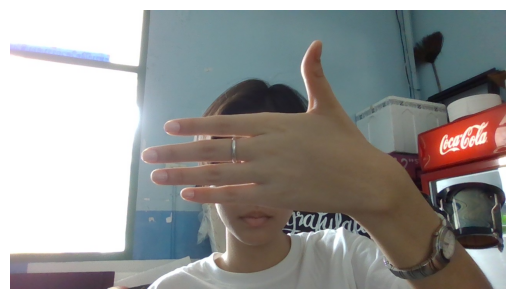

In [3]:
import cv2, matplotlib.pyplot as plt

img = cv2.imread("data/myhand.jpg")
print("image loaded?", img is not None)
if img is not None:
    print("shape:", img.shape)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp

options = mp.tasks.vision.HandLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path="models/hand_landmarker.task"),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_hands=1,
)
detector = mp.tasks.vision.HandLandmarker.create_from_options(options)

In [5]:
mp_image = mp.Image.create_from_file("data/myhand.jpg")
result = detector.detect(mp_image)

print("hands found:", len(result.hand_landmarks))
print("handedness :", result.handedness[0][0].category_name)

hand = result.hand_landmarks[0]          # list of 21 points
print("number of landmarks:", len(hand))
print("wrist  (0):", hand[0].x, hand[0].y, hand[0].z)
print("index tip (8):", hand[8].x, hand[8].y, hand[8].z)

hands found: 1
handedness : Left
number of landmarks: 21
wrist  (0): 0.7293958067893982 0.6180109977722168 -3.8932430612703683e-08
index tip (8): 0.3250401020050049 0.42524296045303345 -0.05479138344526291


In [6]:
# 1. Turn the 21 fractions into 21 pixel positions
img = cv2.imread("data/myhand.jpg")      # BGR image
h, w = img.shape[:2]                      # shape is (height, width, channels)

points = []
for lm in hand:                           # 'hand' is from your Step 2
    px = int(lm.x * w)
    py = int(lm.y * h)
    points.append((px, py))

print(points[0], points[8])               # wrist and index tip, now in pixels

(933, 444) (416, 306)


In [7]:
# 2. Which landmark connects to which (pairs of landmark numbers)
connections = [
    (0, 1), (1, 2), (2, 3), (3, 4),          # thumb
    (0, 5), (5, 6), (6, 7), (7, 8),          # index
    (5, 9), (9, 10), (10, 11), (11, 12),     # middle
    (9, 13), (13, 14), (14, 15), (15, 16),   # ring
    (13, 17), (17, 18), (18, 19), (19, 20),  # pinky
    (0, 17),                                  # edge of the palm
]

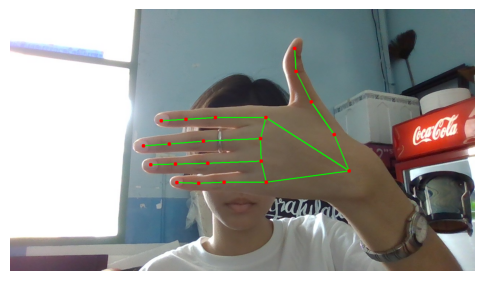

In [8]:
# 3. Draw lines first, then dots on top
canvas = img.copy()

for a, b in connections:
    cv2.line(canvas, points[a], points[b], (0, 255, 0), 2)       # green, BGR

for (px, py) in points:
    cv2.circle(canvas, (px, py), 5, (0, 0, 255), -1)             # red filled dot

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))              # BGR -> RGB for Matplotlib
plt.axis("off")
plt.show()